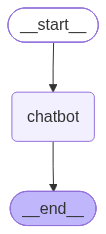

In [ ]:
GROQ_API_KEY="xyz"
#ANGSMITH_API_KEY="xyz"

from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from langchain_groq import ChatGroq

llm = ChatGroq(
    groq_api_key=GROQ_API_KEY,
    model="openai/gpt-oss-120b",
    temperature=0
)

#print(llm)


class State(TypedDict):
    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

#print(graph_builder)

def chatbot(state:State):
    return {"messages":llm.invoke(state['messages'])}

graph_builder.add_node("chatbot",chatbot)

#print(graph_builder)
graph_builder.add_edge(START,"chatbot")
graph_builder.add_edge("chatbot",END)

graph=graph_builder.compile()

from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass



In [2]:
while True:
    user_input = input("User: ")

    # Mistake 1: lower is a method, so use lower()
    if user_input.lower() in ["quit", "q"]:
        print("Bye")
        break
    print("User Input",user_input)
    # Stream events from LangGraph
    
    ggg = graph.stream({"messages": ("user", user_input)})
    #print(ggg)

    for evt in ggg:
        # Mistake 2: Access each event's values
        for value in evt.values():
            # Mistake 3: Print the message content
            print("Assistant:", value["messages"].content)
    

User Input Who is Gandhi
Assistant: Mahatma Mohandas Karamchand Gandhi (1869 – 1948) was an Indian lawyer, political activist, and spiritual leader who became the pre‑eminent figure of the Indian independence movement against British colonial rule.  

**Key points about Gandhi:**

| Aspect | Details |
|--------|---------|
| **Early life** | Born on 2 October 1869 in Porbandar, Gujarat, India. Trained as a barrister in London and practiced law in South Africa, where he first experimented with non‑violent resistance. |
| **Philosophy** | Developed and popularized **Satyagraha** (“truth‑force” or non‑violent civil disobedience) and **Ahimsa** (non‑violence). Emphasized self‑reliance, simple living, and the moral power of truth. |
| **Role in Indian independence** | • Led nationwide campaigns such as the **Non‑Cooperation Movement** (1920‑22), **Salt March** (1930), and **Quit India Movement** (1942). <br>• Mobilized millions of Indians across religious, social, and economic lines. |
| **S